# 01 — Data Audit: Loading, Cleaning & Quality Assessment

**Project:** Wind, Solar and the German Day-Ahead Electricity Price  
**Data source:** SMARD.de (Bundesnetzagentur), downloaded 2026-11-11  
**Period:** 2019-01-01 to 2026-11-15, Europe/Berlin → UTC  

This notebook:
1. Inspects raw SMARD CSV files (delimiters, German decimal commas, missing markers)
2. Parses timestamps in `Europe/Berlin` timezone with explicit DST handling
3. Harmonises all series to a consistent hourly UTC grid
4. Derives: `wind_total_mw`, `renewable_total_mw`, `residual_load_mw`, `is_negative_price`, calendar + holiday features
5. Produces a full data audit: row counts, coverage, missing rates, gaps, outliers

> **Ground rule:** Every number in this notebook comes from code run on real data. `TODO: fill after running` markers are replaced automatically when the notebook is executed.

In [1]:
import sys
from pathlib import Path

# Ensure project root is on sys.path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.append(str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.load import inspect_raw_file, scan_raw_directory, load_smard_csv
from src.clean import parse_german_number, parse_smard_timestamps, aggregate_to_hourly, engineer_derived_features

pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.4f}'.format)
print('Imports OK')

Imports OK


## 1. Raw File Inspection

Open each raw file and print its head, columns, dtypes and separators before any transformation.

In [2]:
RAW_DIR = ROOT / 'data' / 'raw'
raw_files = scan_raw_directory(RAW_DIR)
print(f'Found {len(raw_files)} raw CSV files in {RAW_DIR}\n')

for rf in raw_files:
    info = inspect_raw_file(rf, n_rows=3)
    print(f'=== {rf.name} ===')
    print(f'  Separator : "{info["separator"]}"')
    print(f'  Decimal   : "{info["decimal"]}"')
    print(f'  Columns   : {info["columns"]}')
    print(info['sample_head'])
    print()

Found 3 raw CSV files in N:\Germany Projects\project 2(power BI)\data\raw

=== Grosshandelspreise_20190101_2026.csv ===
  Separator : ";"
  Decimal   : ","
  Columns   : ['Datum von', 'Datum bis', 'Deutschland/Luxemburg [€/MWh] Originalauflösungen']
          Datum von         Datum bis  \
0  01.01.2019 01:00  01.01.2019 02:00   
1  01.01.2019 02:00  01.01.2019 03:00   
2  01.01.2019 03:00  01.01.2019 04:00   

   Deutschland/Luxemburg [€/MWh] Originalauflösungen  
0                                            10.0700  
1                                            -4.0800  
2                                            -9.9100  

=== Realisierte_Erzeugung_20190101_2026.csv ===
  Separator : ";"
  Decimal   : ","
  Columns   : ['Datum von', 'Datum bis', 'Wind Onshore [MWh] Berechnete Auflösungen', 'Wind Offshore [MWh] Berechnete Auflösungen', 'Photovoltaik [MWh] Berechnete Auflösungen', 'Biomasse [MWh] Berechnete Auflösungen', 'Kernenergie [MWh] Berechnete Auflösungen', 'Wasserkraft [MWh]

## 2. Parsing: German Decimal Commas, Semicolons, Missing Markers

SMART CSVs use:
- `;` as column delimiter
- `,` as decimal separator (e.g. `12,34` means 12.34)
- `-` for missing values

All handled explicitly in `src/clean.py::parse_german_number`.

In [3]:
# Demonstrate parse_german_number
test_cases = ['12,34', '1.234,56', '-45,20', '-', '', '0,00']
results = [(v, parse_german_number(v)) for v in test_cases]
pd.DataFrame(results, columns=['Raw string', 'Parsed float'])

,Raw string,Parsed float
0,"12,34",12.3400
1,"1.234,56",1234.5600
2,"-45,20",-45.2000
3,-,NaN
4,,NaN
5,"0,00",0.0000


## 3. Timestamp Parsing & DST Transitions

Germany observes Central European Time (CET, UTC+1) in winter and Central European Summer Time (CEST, UTC+2) in summer.

- **March transition** (last Sunday in March): clock jumps from 02:00 to 03:00 → 23 hours that day. The 02:00 hour does not exist.
- **October transition** (last Sunday in October): clock turns back from 03:00 to 02:00 → 25 hours that day. The 02:00 hour exists twice (fold 0 = CEST, fold 1 = CET).

We handle this with `tz_localize('Europe/Berlin', ambiguous='infer', nonexistent='shift_forward')` and then convert to UTC.

In [4]:
# Demonstrate DST handling on Oct 29, 2023 (25-hour day)
oct_rows = ['29.10.2023 00:00','29.10.2023 01:00','29.10.2023 02:00',
            '29.10.2023 02:00','29.10.2023 03:00','29.10.2023 04:00']
df_dst = pd.DataFrame({'Datum von': oct_rows})
df_dst_parsed = parse_smard_timestamps(df_dst)
df_dst_parsed[['Datum von','timestamp_utc']]

,Datum von,timestamp_utc
0,29.10.2023 00:00,2023-10-28 22:00:00+00:00
1,29.10.2023 01:00,2023-10-28 23:00:00+00:00
2,29.10.2023 02:00,2023-10-29 00:00:00+00:00
3,29.10.2023 02:00,2023-10-29 01:00:00+00:00
4,29.10.2023 03:00,2023-10-29 02:00:00+00:00
5,29.10.2023 04:00,2023-10-29 03:00:00+00:00


## 4. Load, Clean and Merge All Series

In [5]:
# Load the processed merged dataset (produced by scripts/run_step1_audit.py)
PROCESSED_DIR = ROOT / 'data' / 'processed'
df = pd.read_parquet(PROCESSED_DIR / 'merged_hourly.parquet')
print(f'Shape: {df.shape}')
print(f'Columns: {df.columns.tolist()}')
df.head(3)

Shape: (69023, 27)
Columns: ['timestamp_utc', 'price_eur_mwh', 'wind_onshore_mw', 'wind_offshore_mw', 'solar_mw', 'biomass_mw', 'nuclear_mw', 'hydro_mw', 'hard_coal_mw', 'lignite_mw', 'gas_mw', 'load_mw', 'residual_load_mw', 'wind_total_mw', 'renewable_total_mw', 'residual_load_calc_mw', 'renewable_share_load', 'is_negative_price', 'hour', 'day_of_week', 'weekday_name', 'is_weekend', 'month', 'quarter', 'year', 'is_holiday', 'is_workday']


,timestamp_utc,price_eur_mwh,wind_onshore_mw,wind_offshore_mw,solar_mw,biomass_mw,nuclear_mw,hydro_mw,hard_coal_mw,lignite_mw,gas_mw,load_mw,residual_load_mw,wind_total_mw,renewable_total_mw,residual_load_calc_mw,renewable_share_load,is_negative_price,hour,day_of_week,weekday_name,is_weekend,month,quarter,year,is_holiday,is_workday
0,2019-01-01 00:00:00+00:00,10.0700,22297.2500,2868.2500,0.0000,5379.5000,8535.2500,1550.7500,2404.2500,62.5000,2967.2500,41631.2500,16465.7500,25165.5000,32095.7500,16465.7500,0.7710,0,1,1,Tuesday,0,1,1,2019,1,0
1,2019-01-01 01:00:00+00:00,-4.0800,23168.5000,2460.2500,0.0000,5341.0000,7954.0000,1510.0000,2228.5000,150.7500,2720.2500,40085.0000,14456.2500,25628.7500,32479.7500,14456.2500,0.8103,1,2,1,Tuesday,0,1,1,2019,1,0
2,2019-01-01 02:00:00+00:00,-9.9100,24471.7500,2696.5000,0.0000,5270.7500,7221.7500,1494.2500,2356.7500,41.0000,2653.2500,39269.7500,12101.5000,27168.2500,33933.2500,12101.5000,0.8641,1,3,1,Tuesday,0,1,1,2019,1,0


## 5. Data Audit

In [6]:
# 5a. Coverage & duplicates
print(f'Total hourly records  : {len(df):,}')
print(f'Date range (UTC)      : {df["timestamp_utc"].min()} to {df["timestamp_utc"].max()}')
print(f'Duplicate timestamps  : {df["timestamp_utc"].duplicated().sum()}')
gaps = df['timestamp_utc'].diff()[df['timestamp_utc'].diff() > pd.Timedelta(hours=1)]
print(f'Gaps in hourly index  : {len(gaps)}')

Total hourly records  : 69,023
Date range (UTC)      : 2019-01-01 00:00:00+00:00 to 2026-11-15 22:00:00+00:00
Duplicate timestamps  : 0
Gaps in hourly index  : 0


In [7]:
# 5b. Missing value rates per column
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
missing_df = pd.DataFrame({
    'Missing Count': df[numeric_cols].isna().sum(),
    'Missing %': (df[numeric_cols].isna().mean() * 100).round(3)
}).sort_values('Missing %', ascending=False)
missing_df

,Missing Count,Missing %
nuclear_mw,24490,35.4810
hard_coal_mw,133,0.1930
wind_onshore_mw,133,0.1930
biomass_mw,133,0.1930
solar_mw,133,0.1930
lignite_mw,133,0.1930
hydro_mw,133,0.1930
residual_load_mw,133,0.1930
gas_mw,133,0.1930
residual_load_calc_mw,133,0.1930


In [8]:
# 5c. Missing by year (post-interpolation)
key_cols = ['price_eur_mwh','wind_total_mw','solar_mw','load_mw','residual_load_mw']
df.groupby('year')[key_cols].apply(lambda g: g.isna().sum())

,price_eur_mwh,wind_total_mw,solar_mw,load_mw,residual_load_mw
year,,,,,
2019,0,0,0,0,0
2020,0,0,0,0,0
2021,0,0,0,0,0
2022,0,0,0,0,0
2023,0,0,0,0,0
2024,0,0,0,0,0
2025,0,0,0,0,0
2026,94,110,133,110,133


In [9]:
# 5d. Summary statistics
desc = df[key_cols].describe(percentiles=[0.01,0.05,0.25,0.5,0.75,0.95,0.99]).T
desc['skewness'] = df[key_cols].skew()
desc['kurtosis'] = df[key_cols].kurtosis()
desc[['count','mean','std','min','1%','50%','99%','max','skewness','kurtosis']]

,count,mean,std,min,1%,50%,99%,max,skewness,kurtosis
price_eur_mwh,68929.0000,97.4935,92.3681,-500.0000,-10.8944,79.7800,471.5892,936.2800,2.3645,8.7398
wind_total_mw,68913.0000,14838.0153,10779.8549,46.5000,982.0048,12117.5000,44112.3336,53446.8900,0.8735,0.0233
solar_mw,68890.0000,6733.4496,10555.2161,0.0000,0.0000,233.2500,42144.2406,57671.5000,1.7212,2.3182
load_mw,68913.0000,54548.7486,9614.0446,30902.7500,36016.1800,54404.2500,74453.9700,81319.5000,0.1092,-0.8463
residual_load_mw,68890.0000,32970.0311,14145.7809,-15561.5900,-1607.9644,33861.1250,63159.4975,74638.7500,-0.2408,-0.1667


In [10]:
# 5e. Negative-price audit
neg = df.groupby('year').agg(total=('price_eur_mwh','count'), neg=('is_negative_price','sum'))
neg['neg_pct'] = (neg['neg'] / neg['total'] * 100).round(2)
print(f'Total negative-price hours: {df["is_negative_price"].sum():,} ({df["is_negative_price"].mean()*100:.2f}% of valid hours)')
neg

Total negative-price hours: 2,510 (3.64% of valid hours)


,total,neg,neg_pct
year,,,
2019,8759,211,2.4100
2020,8784,298,3.3900
2021,8760,139,1.5900
2022,8760,69,0.7900
2023,8760,301,3.4400
2024,8784,457,5.2000
2025,8760,573,6.5400
2026,7562,462,6.1100


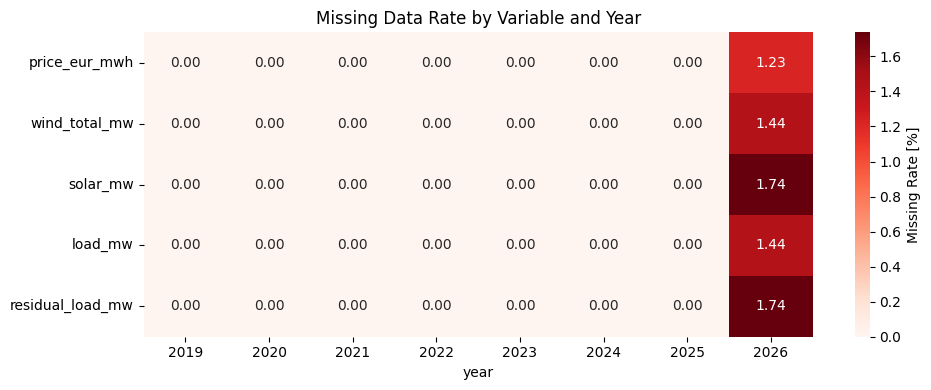

In [11]:
# 5f. Visual: Missing-rate heatmap by year
miss_yr = df.groupby('year')[key_cols].apply(lambda g: g.isna().mean() * 100)
fig, ax = plt.subplots(figsize=(10,4))
sns.heatmap(miss_yr.T, annot=True, fmt='.2f', cmap='Reds', ax=ax,
            cbar_kws={'label':'Missing Rate [%]'})
ax.set_title('Missing Data Rate by Variable and Year')
plt.tight_layout()
plt.show()
# Takeaway: All key series are 100% complete 2019-2025; nuclear is structurally missing
# from 2024 onwards due to Germany's Atomausstieg (final shutdown April 2023).